In [89]:
# Initialisation
#  echo: false
# Recharge automatiquement les modules modifiés (évite de redémarrer le kernel)
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as sci
from scipy.signal import hilbert
from scipy.stats import kurtosis
from scipy.fftpack import fft, fftfreq
from IPython.display import Markdown

# Cherche le dossier racine du projet (BDS_Fault_Detection) pour faire les imports depuis Sources/
dossier = Path().resolve()
for parent in (dossier, *dossier.parents):
    if "BDS_Fault_Detection" in parent.name:
        RACINE = parent
sys.path.insert(0, str(RACINE))

# Importation des fonctions du projet (dossier Sources/). Attention de l'ordre d'importation  !
from Sources import data, config, signaux, indicateurs, features, models


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [90]:
# Sélection du scope de données à traiter (sources, défauts, diamètres, positions, charges, canaux)
selection = data.selectionner(
    sources=("12kDE", "12kFE", "Normal"),
    defauts=("IR", "B", "OR"),
    diametres=(7, 14, 21), positions_or=("6",),
    charges=(0, 1, 2, 3),
    canaux={"12kDE": ("DE",), 
            "12kFE": ("FE",), 
            "Normal": ("DE","FE")},
)

In [91]:
# Importation des données sélectionnées et ajout des indicateurs temporels et spectraux (ajout de ceux de Mourad)
table = features.construire_table_SpecMourad(selection, data.charger)

In [92]:
# Preparation pour le modeling + modeling
#| label: preparation-modeling
#| code-summary: "Split par fichier + standardisation"
#| tbl-cap: "Répartition des fichiers entre apprentissage et test."
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lazypredict import LazyClassifier

vues_X = {}       # indics -> X_train.head()
vues_split = {}   # (contexte, target) -> DataFrame des répartition train/test
resultats = []
for contexte in ["DE→DE", "DE→FE"]:
    for target in ["defaut", "classe"]:
        for indics in ["Spectre Robin", "Spectre Mourad"]:
            if indics == "Spectre Robin":
                COLONNES_INDICATEURS = indicateurs.COLONNES_TEMPORELS + indicateurs.COLONNES_SPECTRAUX
            elif indics == "Spectre Mourad":
                COLONNES_INDICATEURS = indicateurs.COLONNES_TEMPORELS + indicateurs.COLONNES_Mourad

            if contexte == "DE→DE":
                X_train, X_test, y_train, y_test, g_train, g_test = features.preparer_modeling(table, COLONNES_INDICATEURS, target=target)
            elif contexte == "DE→FE":
                X_train, X_test, y_train, y_test, g_train, g_test = features.preparer_modeling_DE_FE(table, COLONNES_INDICATEURS, canal_train="DE", canal_test="FE", target=target)
            
            X_train, y_train, X_test, y_test = features.equilibrer(X_train, y_train, X_test, y_test, type="train")

            vues_X[indics] = X_train.head()          # head = les colonnes (features), peu importe le split
            if contexte == "DE→DE":
                vues_split[(contexte, target)] = pd.DataFrame(
                    {"train DE": y_train.value_counts(), "test DE": y_test.value_counts()})
            else:  # DE→FE
                vues_split[(contexte, target)] = pd.DataFrame(
                    {"train DE": y_train.value_counts(), "test FE": y_test.value_counts()})


            clf = LazyClassifier(verbose=0,ignore_warnings=True, custom_metric=None)
            models,predictions = clf.fit(X_train, X_test, y_train, y_test)
            models

            models["scoreTOT"]   = np.sqrt(models["Balanced Accuracy"] * models["F1 Score"])
            models["scoreTimed"] = models["scoreTOT"]**2 / np.log1p(models["Time Taken"] * 10000)

            # --- enregistrement du meilleur modèle de cette config ---
            best = models["scoreTimed"].idxmax()        # idxmax ignore les NaN
            resultats.append({
                "Train→Test": contexte, "target": target, "features": indics,
                "modele": best,
                **models.loc[best, ["Accuracy", "Balanced Accuracy", "ROC AUC",
                                    "F1 Score", "scoreTOT", "Time Taken", "scoreTimed"]].to_dict(),
            })

df_resultats = pd.DataFrame(resultats)
df_resultats

for indics, head in vues_X.items():
    print(f"===== X_train.head() — indics = {indics} =====")
    display(head)

for (contexte, target), df_counts in vues_split.items():
    print(f"===== répartition train/test — contexte={contexte}, target={target} =====")
    display(df_counts)

===== X_train.head() — indics = Spectre Robin =====


,RMS,Pic,Crete,Kurtosis,amp_BPFI_1,amp_BPFI_2,amp_BPFI_3,amp_BPFO_1,amp_BPFO_2,amp_BPFO_3,amp_BSF_1,amp_BSF_2,amp_BSF_3,amp_FTF_1,amp_FTF_2,amp_FTF_3,ratio_BPFI,ratio_BPFO,ratio_BSF,ratio_FTF
780,-0.847735,-0.781768,-0.780604,-0.650465,-0.725800,-0.725966,-0.603650,-0.565136,-0.585202,-0.725911,-0.620317,-0.919308,-0.601615,-0.787837,-0.652614,-0.651592,-0.224303,-0.913742,1.224345,0.671216
81,-0.796443,-0.779470,-0.980288,-0.686600,-0.730638,-0.716700,-0.596515,-0.548613,-0.576415,-0.716646,-0.608321,-0.761304,-0.616449,-0.659176,-0.539195,-0.549444,-1.142964,-0.212722,-0.232075,1.838096
77,-0.783754,-0.777603,-1.009861,-0.688146,-0.725264,-0.723930,-0.599593,-0.549732,-0.578699,-0.723875,-0.603641,-0.931533,-0.596463,-0.671538,-0.531648,-0.538230,-0.961148,-0.304105,0.019669,1.573235
309,-0.822640,-0.769992,-0.777564,-0.670050,-0.730716,-0.725472,-0.609288,-0.561481,-0.574960,-0.725417,-0.615008,-0.936464,-0.629029,-0.732258,-0.625770,-0.626069,-0.923070,-0.752710,0.543722,1.751643
621,-0.841750,-0.743998,-0.405766,-0.629525,-0.731696,-0.735625,-0.580797,-0.565026,-0.573764,-0.735569,-0.626604,-0.864944,-0.626332,-0.783576,-0.643557,-0.643883,-0.620246,-0.757983,0.732337,1.266960


===== X_train.head() — indics = Spectre Mourad =====


,RMS,Pic,Crete,Kurtosis,RMS_bande,Env_BPFI,Env_BPFO,Env_BSF,Env_FTF
780,-0.847735,-0.781768,-0.780604,-0.650465,-0.894288,-0.770082,-0.745657,-1.302922,-0.302520
81,-0.796443,-0.779470,-0.980288,-0.686600,-0.872467,-0.599747,-0.479576,0.029537,3.349635
77,-0.783754,-0.777603,-1.009861,-0.688146,-0.868757,-0.719971,-0.442373,-0.282364,3.004450
309,-0.822640,-0.769992,-0.777564,-0.670050,-0.894869,-0.851574,-0.672093,-1.046307,0.389558
621,-0.841750,-0.743998,-0.405766,-0.629525,-0.892438,-0.787637,-0.742498,-0.922450,-0.173352


===== répartition train/test — contexte=DE→DE, target=defaut =====


,train DE,test DE
defaut,,
B,702,300
IR,702,300
OR,702,201
Sain,702,404


... (2 outputs left out)

===== répartition train/test — contexte=DE→FE, target=defaut =====


,train DE,test FE
defaut,,
Sain,601,706
IR,601,600
B,601,600
OR,601,300


===== répartition train/test — contexte=DE→FE, target=classe =====


,train DE,test FE
classe,,
B007,200,200
B014,200,200
B021,200,200
IR007,200,200
IR014,200,200
IR021,200,200
OR007,200,200
OR014,200,50
OR021,200,50


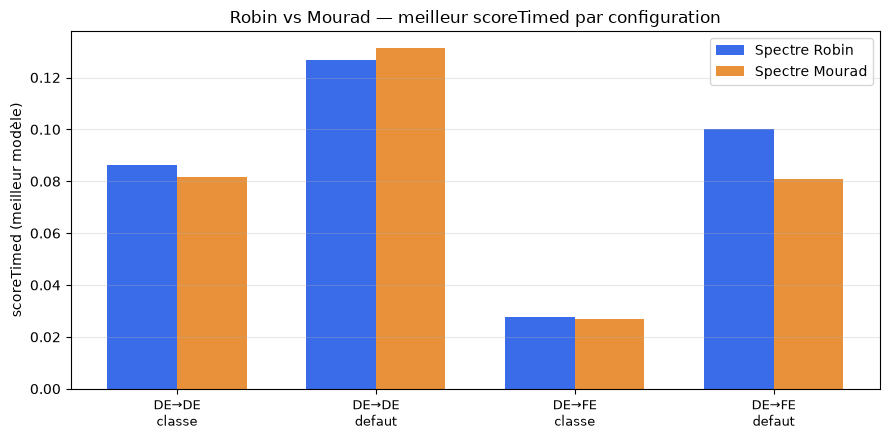

In [95]:
piv = df_resultats.pivot_table(index=["Train→Test", "target"], columns="features", values="scoreTimed")
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(piv)); w = 0.35
ax.bar(x - w/2, piv["Spectre Robin"],  w, label="Spectre Robin",  color="#3A6BE8")
ax.bar(x + w/2, piv["Spectre Mourad"], w, label="Spectre Mourad", color="#E8913A")
ax.set_xticks(x, [f"{c}\n{t}" for c, t in piv.index], fontsize=9)
ax.set_ylabel("scoreTimed (meilleur modèle)")
ax.set_title("Robin vs Mourad — meilleur scoreTimed par configuration")
ax.legend(); ax.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()